# E-Commerce Customer & Revenue Intelligence Analytics
## Phase 3: Comprehensive Customer & Revenue Analysis
**Author:** Vansh Kesarwani  
**Role Focus:** Entry-Level Data Analyst Portfolio / Internship Project  
**Dataset:** Olist Brazilian E-Commerce Dataset (Kaggle)

---
### Analysis Structure
1. **Environment Setup & Data Loading**
2. **Foundational Financial & Customer KPI Calculations**
3. **Monthly Revenue Dynamics, Seasonality & Growth Rates**
4. **Product Category Performance (The Pareto Principle)**
5. **Customer Purchasing Behavior & Geographic Concentration**
6. **RFM Analysis & Customer Segmentation**
7. **Customer Cohort Retention Analysis (Heatmap)**
8. **Repurchase Time-Lag & Cycle Analysis**
9. **10 Major Business Insights & Strategic Recommendations**


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Styling
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11
sns.set_theme(style="whitegrid", palette="muted")

CLEAN_DIR = "../dataset/cleaned"
FIGURES_DIR = "../reports/figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

# Load clean data
df_orders = pd.read_csv(os.path.join(CLEAN_DIR, "orders_cleaned.csv"))
df_items = pd.read_csv(os.path.join(CLEAN_DIR, "order_items_cleaned.csv"))
df_cust = pd.read_csv(os.path.join(CLEAN_DIR, "customers_cleaned.csv"))
df_products = pd.read_csv(os.path.join(CLEAN_DIR, "products_cleaned.csv"))
df_payments = pd.read_csv(os.path.join(CLEAN_DIR, "order_payments_cleaned.csv"))

for col in ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]:
    df_orders[col] = pd.to_datetime(df_orders[col])

# Scope: Completed delivered orders for recognized revenue
delivered_orders = df_orders[df_orders["order_status"] == "delivered"].copy()
delivered_order_ids = set(delivered_orders["order_id"])
delivered_items = df_items[df_items["order_id"].isin(delivered_order_ids)].copy()
delivered_customers = delivered_orders.merge(df_cust[["customer_id", "customer_unique_id", "customer_city", "customer_state"]], on="customer_id", how="left")

print(f"Loaded {len(delivered_orders):,} delivered orders and {len(delivered_items):,} item lines.")

Loaded 96,478 delivered orders and 110,197 item lines.


### 1. Foundational Revenue & Customer KPI Scorecard

In [2]:
total_gmv = delivered_items["price"].sum()
total_freight = delivered_items["freight_value"].sum()
total_gross_spend = total_gmv + total_freight
total_orders = delivered_orders["order_id"].nunique()
total_unique_cust = delivered_customers["customer_unique_id"].nunique()
aov = total_gmv / total_orders
arpc = total_gmv / total_unique_cust
basket_depth = len(delivered_items) / total_orders
freight_ratio = (total_freight / total_gmv) * 100

kpi_df = pd.DataFrame([
    {"Metric": "Gross Merchandise Value (GMV)", "Value": f"R$ {total_gmv:,.2f}"},
    {"Metric": "Total Freight Collected", "Value": f"R$ {total_freight:,.2f}"},
    {"Metric": "Total Customer Cash Inflow", "Value": f"R$ {total_gross_spend:,.2f}"},
    {"Metric": "Total Delivered Orders", "Value": f"{total_orders:,}"},
    {"Metric": "Total Unique Customers", "Value": f"{total_unique_cust:,}"},
    {"Metric": "Average Order Value (AOV)", "Value": f"R$ {aov:,.2f}"},
    {"Metric": "Avg Revenue Per Customer (ARPC)", "Value": f"R$ {arpc:,.2f}"},
    {"Metric": "Average Basket Depth", "Value": f"{basket_depth:.2f} items/order"},
    {"Metric": "Freight-to-Price Ratio", "Value": f"{freight_ratio:.2f}%"}
])
display(kpi_df)

                            Metric             Value
0    Gross Merchandise Value (GMV)  R$ 13,221,498.11
1          Total Freight Collected   R$ 2,198,275.64
2       Total Customer Cash Inflow  R$ 15,419,773.75
3           Total Delivered Orders            96,478
4           Total Unique Customers            93,358
5        Average Order Value (AOV)         R$ 137.04
6  Avg Revenue Per Customer (ARPC)         R$ 141.62
7             Average Basket Depth  1.14 items/order
8           Freight-to-Price Ratio            16.63%


### 2. Monthly Revenue Trajectory & Seasonality

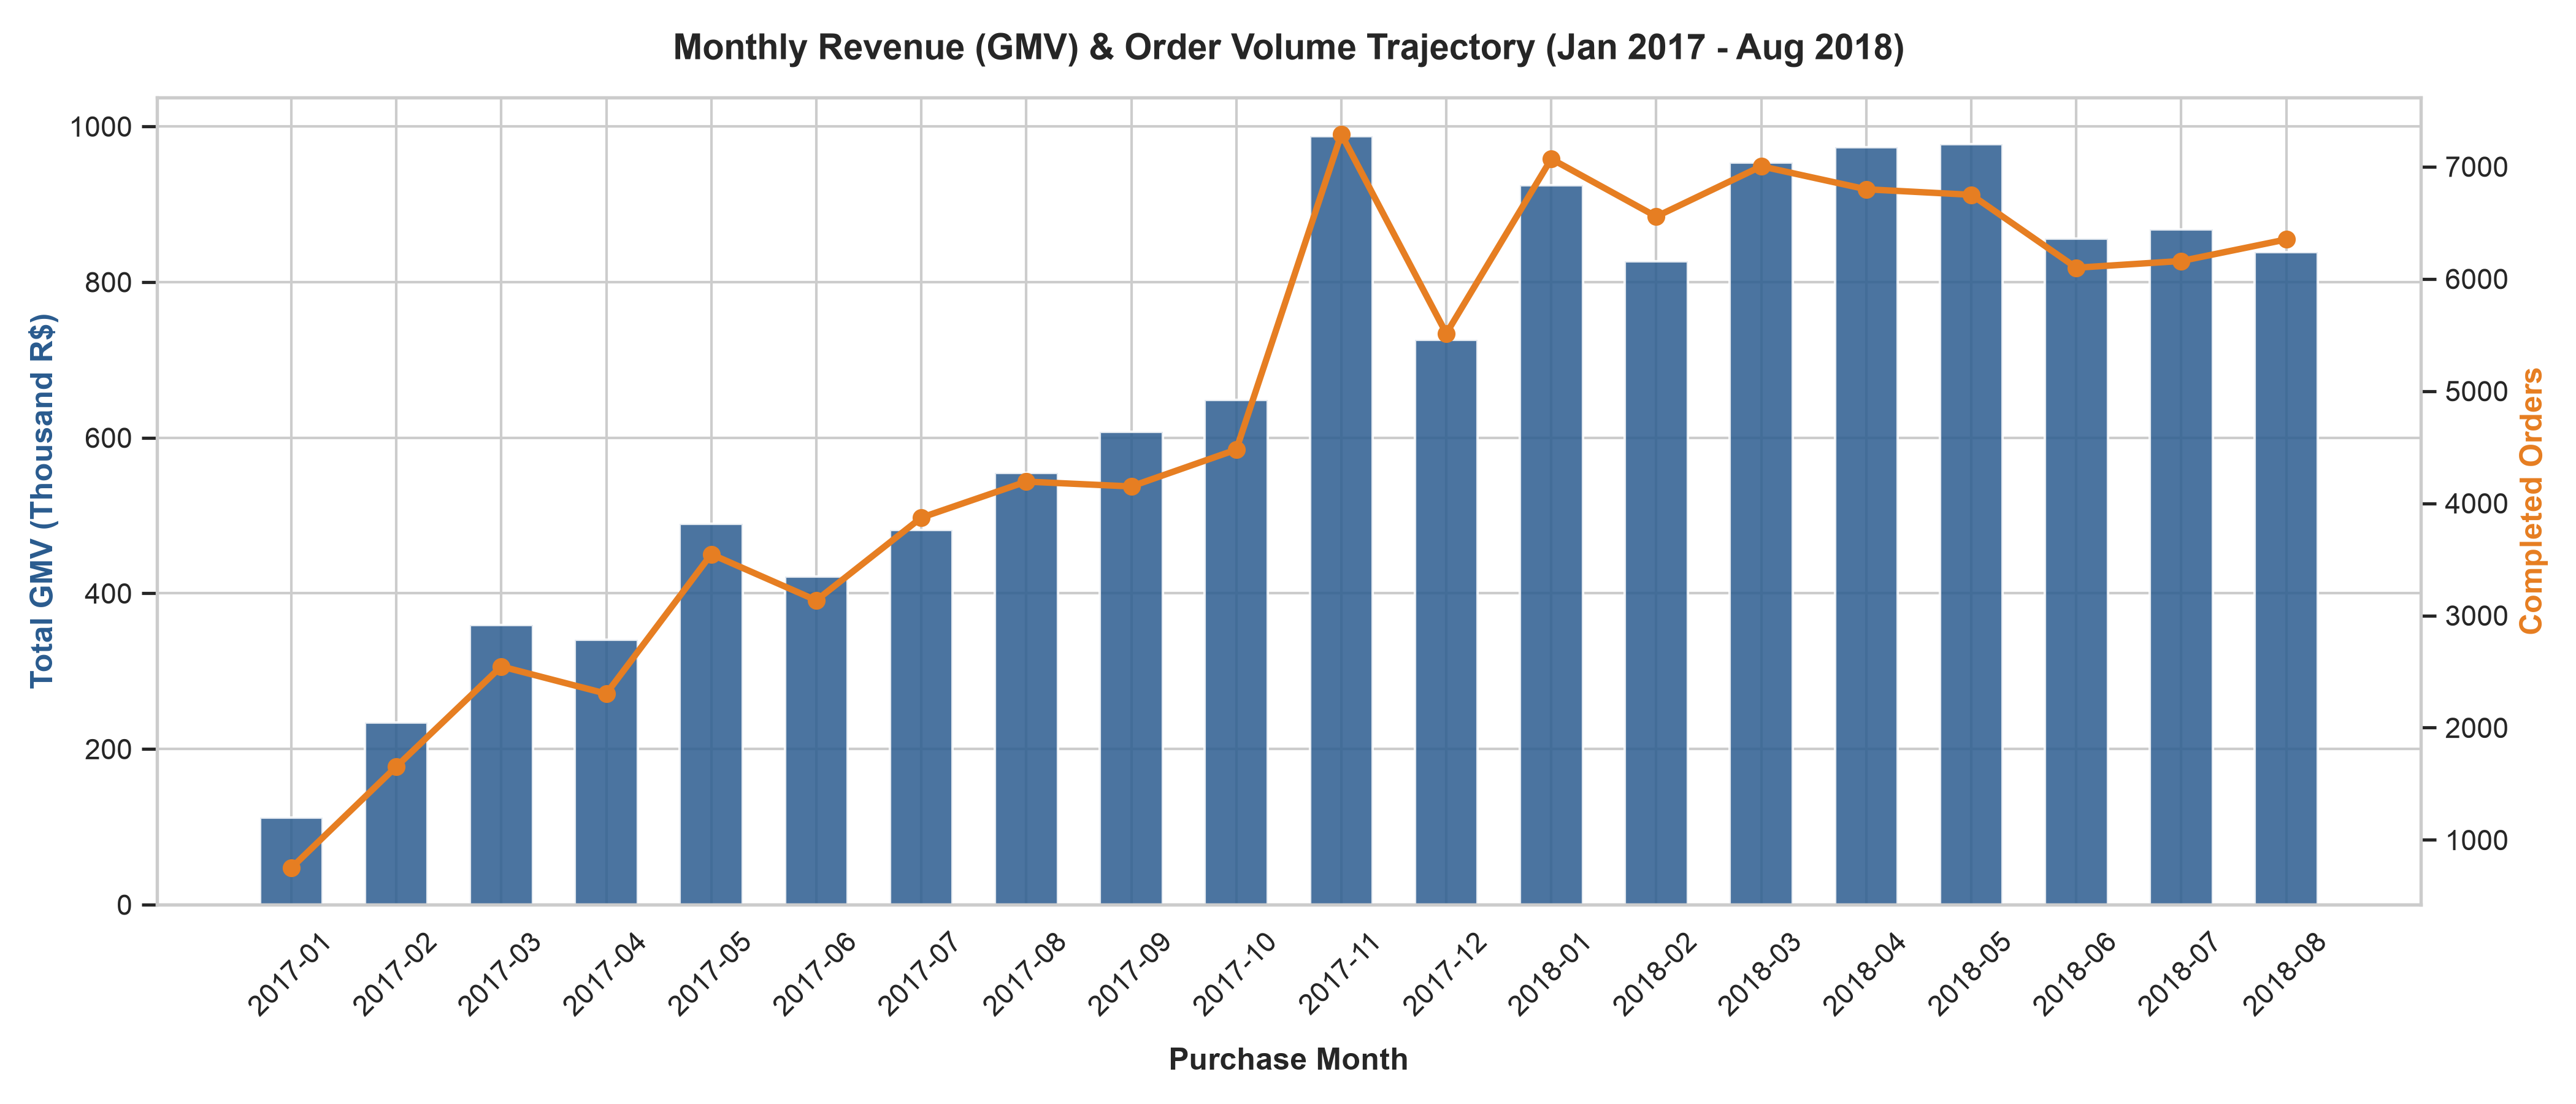

In [3]:
delivered_orders["year_month"] = delivered_orders["order_purchase_timestamp"].dt.to_period("M").astype(str)
df_merged = delivered_orders.merge(delivered_items[["order_id", "product_id", "price", "freight_value"]], on="order_id", how="inner").merge(df_products[["product_id", "category_clean"]], on="product_id", how="left")

monthly = df_merged.groupby("year_month").agg(
    total_gmv=("price", "sum"),
    total_orders=("order_id", "nunique")
).reset_index()

monthly_active = monthly[(monthly["year_month"] >= "2017-01") & (monthly["year_month"] <= "2018-08")].copy()
monthly_active["mom_growth"] = monthly_active["total_gmv"].pct_change() * 100

fig, ax1 = plt.subplots(figsize=(14, 6))
bars = ax1.bar(monthly_active["year_month"], monthly_active["total_gmv"] / 1e3, color="#2b5c8f", alpha=0.85, width=0.6, label="GMV (k R$)")
ax1.set_xlabel("Purchase Month", fontsize=12, fontweight="bold", labelpad=10)
ax1.set_ylabel("Total GMV (Thousand R$)", fontsize=12, fontweight="bold", color="#2b5c8f")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.plot(monthly_active["year_month"], monthly_active["total_orders"], color="#e67e22", marker="o", linewidth=2.5, label="Orders")
ax2.set_ylabel("Completed Orders", fontsize=12, fontweight="bold", color="#e67e22")
ax2.grid(False)

plt.title("Monthly Revenue (GMV) & Order Volume Trajectory (Jan 2017 - Aug 2018)", fontsize=14, fontweight="bold", pad=15)
fig.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "01_monthly_revenue_trend.png"), dpi=300)
plt.show()

### 3. Product Category Concentration (The Pareto Principle)

           category_clean     revenue  units   avg_price  revenue_share
43          Health Beauty  1233131.72   9465  130.283330       9.326717
73          Watches Gifts  1166176.98   5859  199.040276       8.820309
7          Bed Bath Table  1023434.76  10953   93.438762       7.740687
68         Sports Leisure   954852.55   8431  113.254958       7.221969
15  Computers Accessories   888724.61   7644  116.264339       6.721815
39        Furniture Decor   711927.69   8160   87.246040       5.384622
49             Housewares   615628.69   6795   90.600249       4.656270
20             Cool Stuff   610204.10   3718  164.121598       4.615242
5                    Auto   578966.65   4140  139.847017       4.378979
72                   Toys   471286.48   4030  116.944536       3.564547


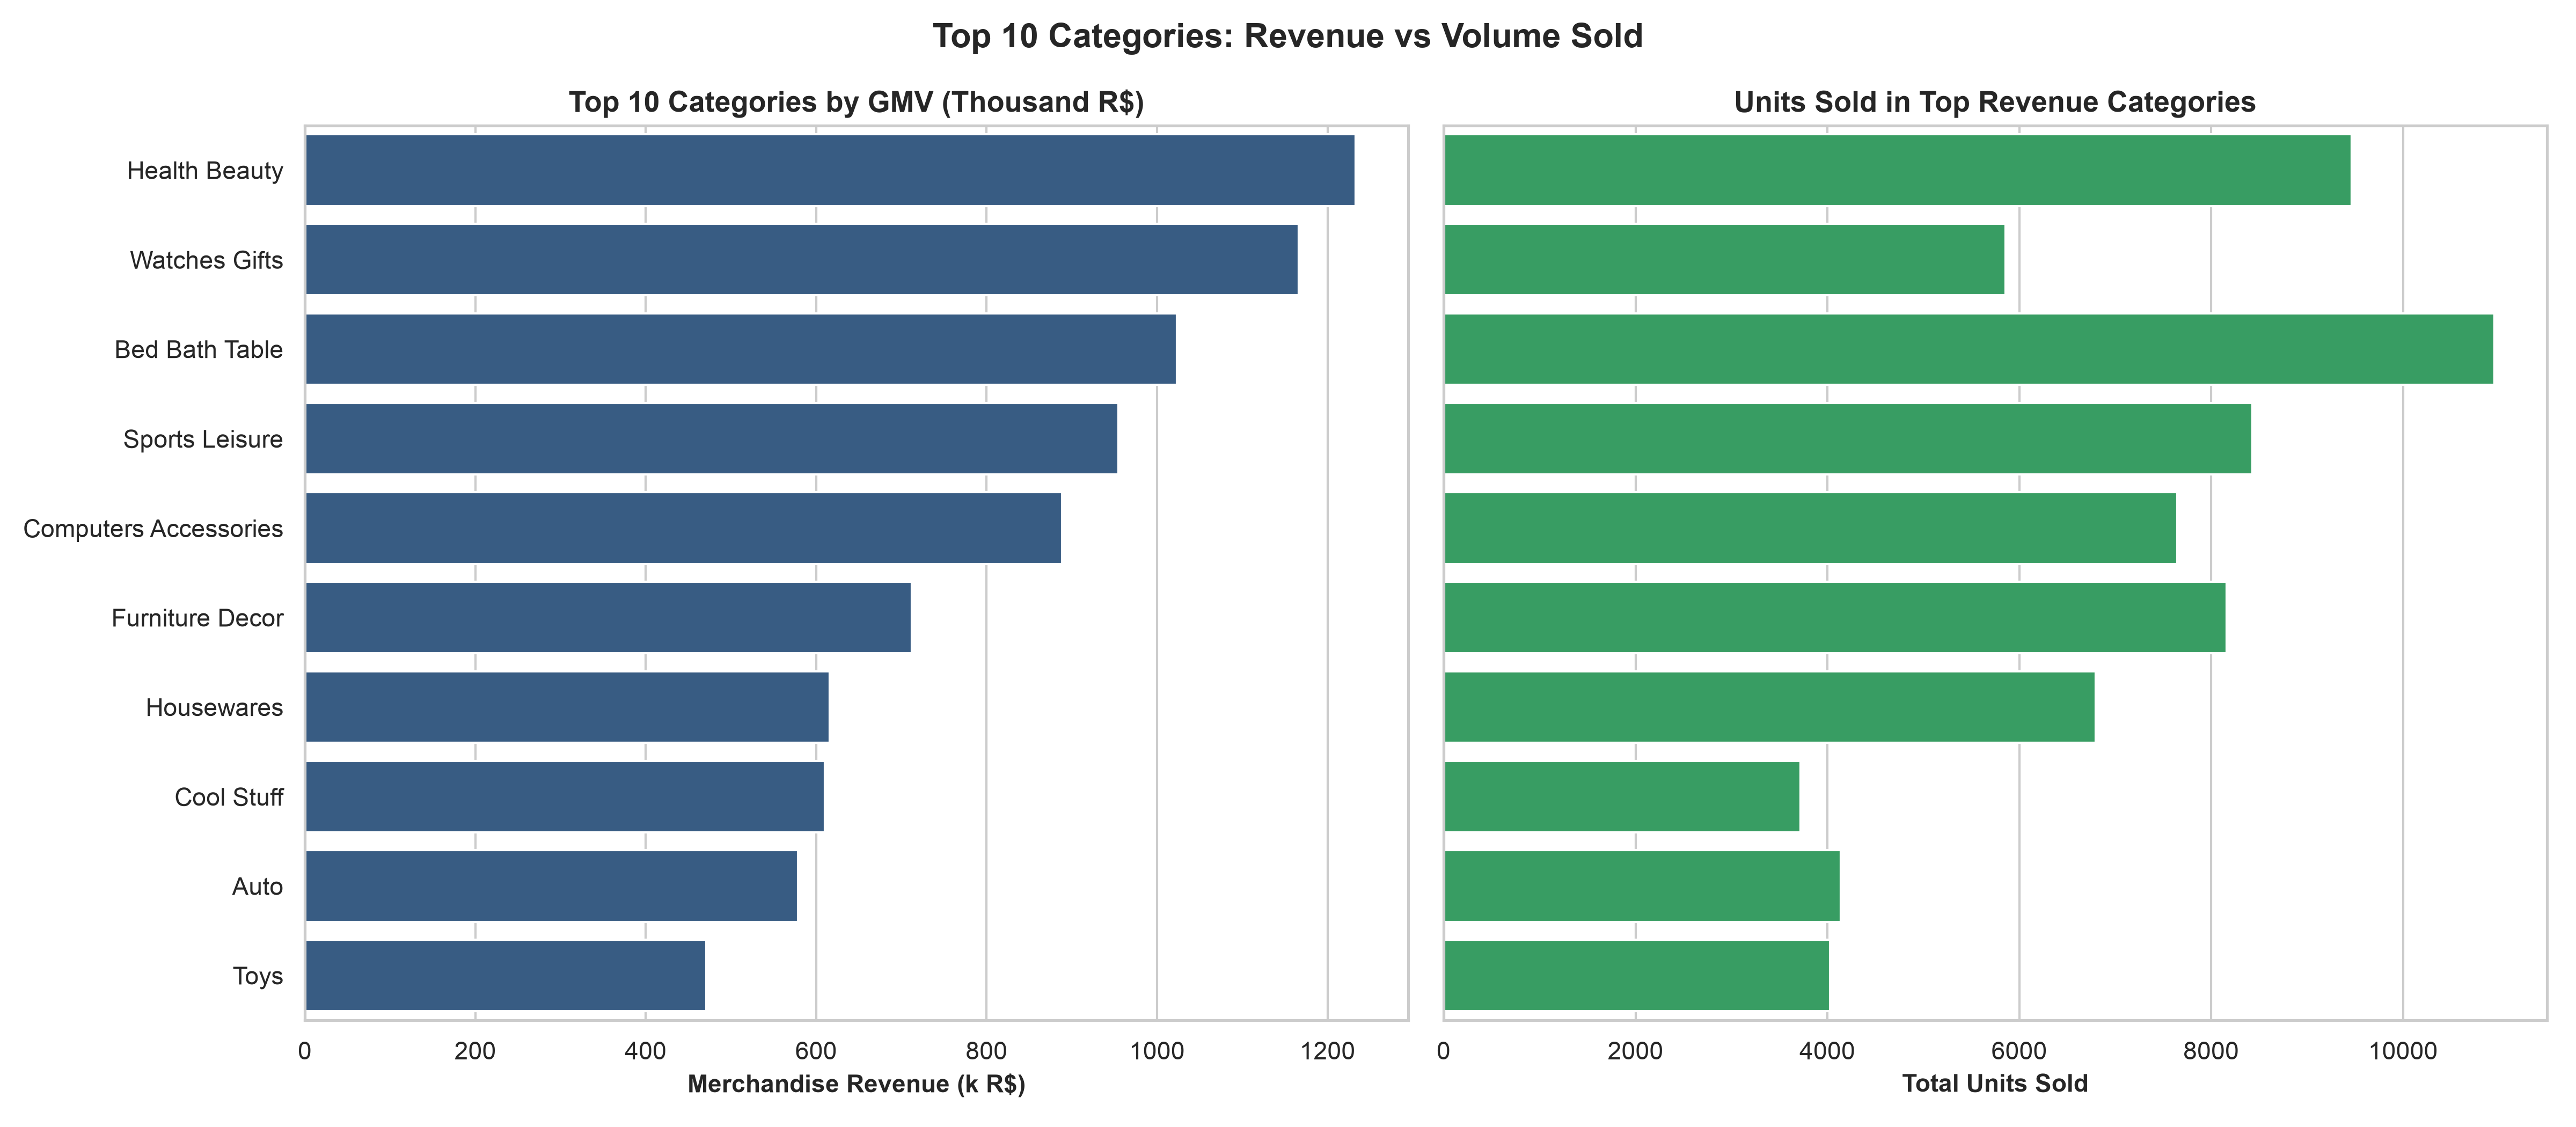

In [4]:
cat_perf = df_merged.groupby("category_clean").agg(
    revenue=("price", "sum"),
    units=("order_id", "count"),
    avg_price=("price", "mean")
).reset_index().sort_values(by="revenue", ascending=False)
cat_perf["revenue_share"] = (cat_perf["revenue"] / cat_perf["revenue"].sum()) * 100
display(cat_perf.head(10))

fig, (ax_rev, ax_unit) = plt.subplots(1, 2, figsize=(16, 7))
top10 = cat_perf.head(10)
sns.barplot(data=top10, y="category_clean", x=top10["revenue"] / 1e3, ax=ax_rev, color="#2b5c8f")
ax_rev.set_title("Top 10 Categories by GMV (Thousand R$)", fontsize=13, fontweight="bold")
ax_rev.set_xlabel("Merchandise Revenue (k R$)", fontsize=11, fontweight="bold")
ax_rev.set_ylabel("")

sns.barplot(data=top10, y="category_clean", x="units", ax=ax_unit, color="#27ae60")
ax_unit.set_title("Units Sold in Top Revenue Categories", fontsize=13, fontweight="bold")
ax_unit.set_xlabel("Total Units Sold", fontsize=11, fontweight="bold")
ax_unit.set_ylabel("")
ax_unit.set_yticklabels([])
plt.suptitle("Top 10 Categories: Revenue vs Volume Sold", fontsize=15, fontweight="bold", y=0.98)
fig.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "02_top_categories_performance.png"), dpi=300)
plt.show()

### 4. RFM Customer Segmentation Model

      Customer_Segment  Customer_Count  ...  Customer_Share  Revenue_Share
7  Potential Loyalists           21191  ...       22.698644      33.852776
0              At Risk            7412  ...        7.939330      22.412614
5       Need Attention           10376  ...       11.114206      15.433551
3       Lost Customers           22412  ...       24.006513      10.586205
2          Hibernating           14568  ...       15.604447       8.407429
4      Loyal Customers            1429  ...        1.530667       2.397444
1            Champions             937  ...        1.003663       2.318057
6        New Customers            7601  ...        8.141777       2.312067
8            Promising            7432  ...        7.960753       2.279857

[9 rows x 5 columns]


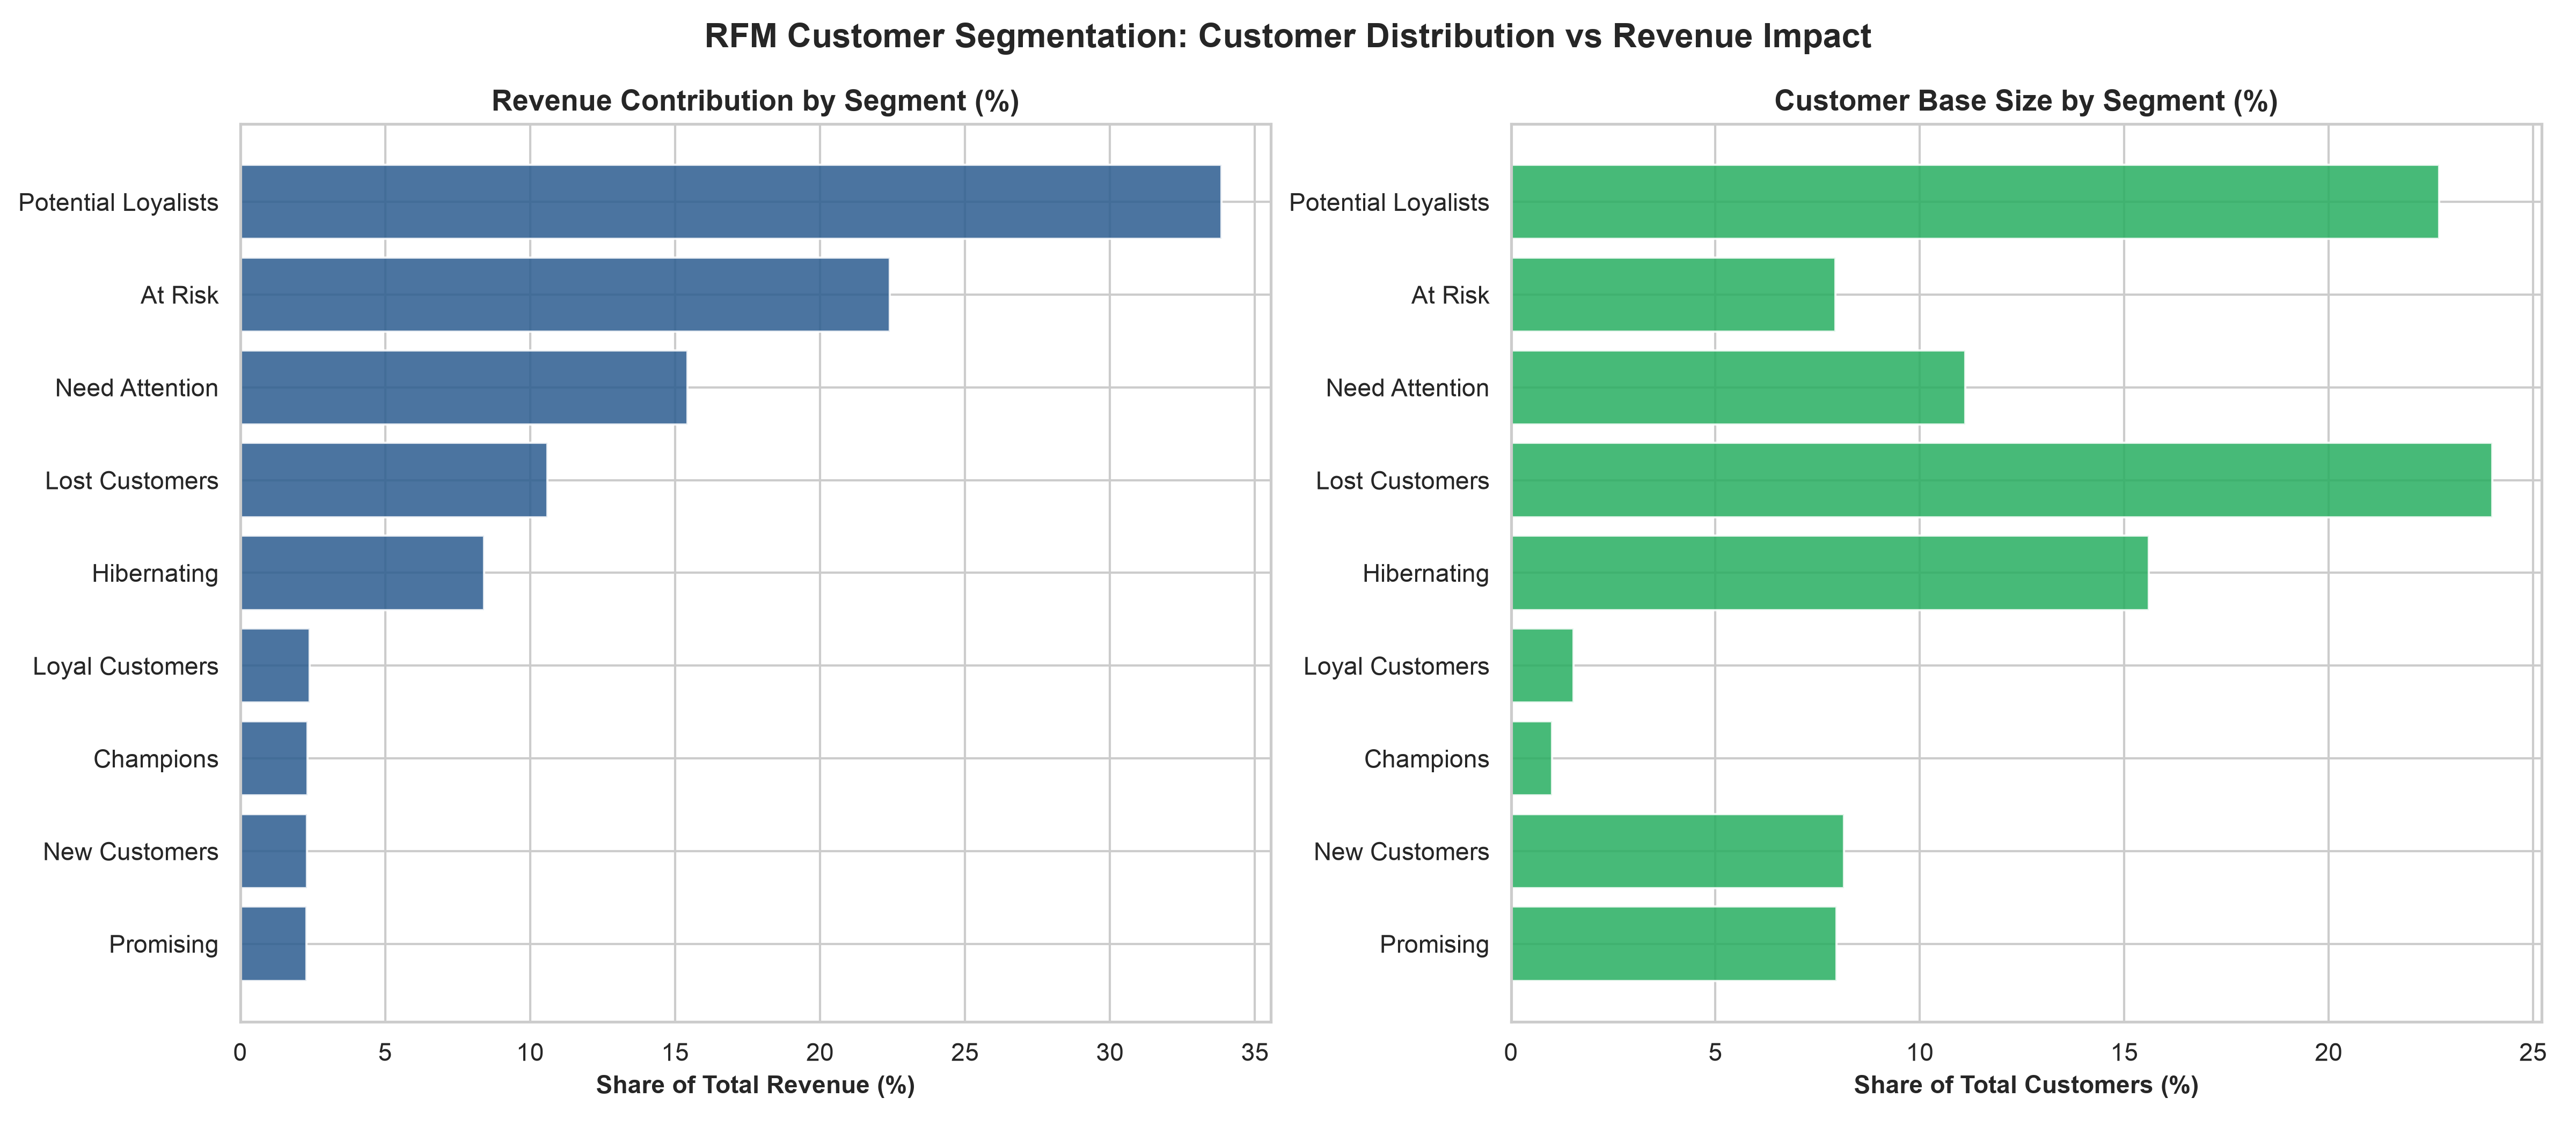

In [5]:
order_agg = delivered_orders.merge(df_cust[["customer_id", "customer_unique_id"]], on="customer_id", how="inner").merge(delivered_items[["order_id", "price"]], on="order_id", how="inner").groupby(["order_id", "customer_unique_id"]).agg(
    order_date=("order_purchase_timestamp", "max"),
    order_val=("price", "sum")
).reset_index()

snapshot_date = order_agg["order_date"].max() + pd.Timedelta(days=1)
rfm = order_agg.groupby("customer_unique_id").agg(
    Recency=("order_date", lambda x: (snapshot_date - x.max()).days),
    Frequency=("order_id", "count"),
    Monetary=("order_val", "sum")
).reset_index()

rfm["R_score"] = pd.qcut(rfm["Recency"], q=5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["M_score"] = pd.qcut(rfm["Monetary"], q=5, labels=[1, 2, 3, 4, 5]).astype(int)

def assign_f_score(f):
    if f >= 4: return 5
    elif f == 3: return 4
    elif f == 2: return 3
    return 1
rfm["F_score"] = rfm["Frequency"].apply(assign_f_score)

def assign_segment(row):
    r, f, m = row["R_score"], row["F_score"], row["M_score"]
    if r >= 4 and f >= 3 and m >= 4: return "Champions"
    elif f >= 3 and r >= 2: return "Loyal Customers"
    elif r >= 4 and (m >= 3 or f >= 3): return "Potential Loyalists"
    elif r == 5 and f == 1: return "New Customers"
    elif r == 4 and f == 1: return "Promising"
    elif (f >= 3 or m == 5) and r <= 2: return "At Risk"
    elif r == 3 and m >= 3: return "Need Attention"
    elif r == 2: return "Hibernating"
    else: return "Lost Customers"

rfm["Customer_Segment"] = rfm.apply(assign_segment, axis=1)
rfm.to_csv(os.path.join(CLEAN_DIR, "rfm_customer_segments.csv"), index=False)

seg_summary = rfm.groupby("Customer_Segment").agg(
    Customer_Count=("customer_unique_id", "count"),
    Total_Monetary=("Monetary", "sum")
).reset_index()
seg_summary["Customer_Share"] = (seg_summary["Customer_Count"] / len(rfm)) * 100
seg_summary["Revenue_Share"] = (seg_summary["Total_Monetary"] / rfm["Monetary"].sum()) * 100
seg_summary = seg_summary.sort_values(by="Revenue_Share", ascending=True)
display(seg_summary.sort_values(by="Revenue_Share", ascending=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
ax1.barh(seg_summary["Customer_Segment"], seg_summary["Revenue_Share"], color="#2b5c8f", alpha=0.85)
ax1.set_title("Revenue Contribution by Segment (%)", fontsize=13, fontweight="bold")
ax1.set_xlabel("Share of Total Revenue (%)", fontsize=11, fontweight="bold")
ax2.barh(seg_summary["Customer_Segment"], seg_summary["Customer_Share"], color="#27ae60", alpha=0.85)
ax2.set_title("Customer Base Size by Segment (%)", fontsize=13, fontweight="bold")
ax2.set_xlabel("Share of Total Customers (%)", fontsize=11, fontweight="bold")
plt.suptitle("RFM Customer Segmentation: Customer Distribution vs Revenue Impact", fontsize=15, fontweight="bold", y=0.98)
fig.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "03_rfm_customer_segments.png"), dpi=300)
plt.show()

### 5. Customer Cohort Retention Analysis

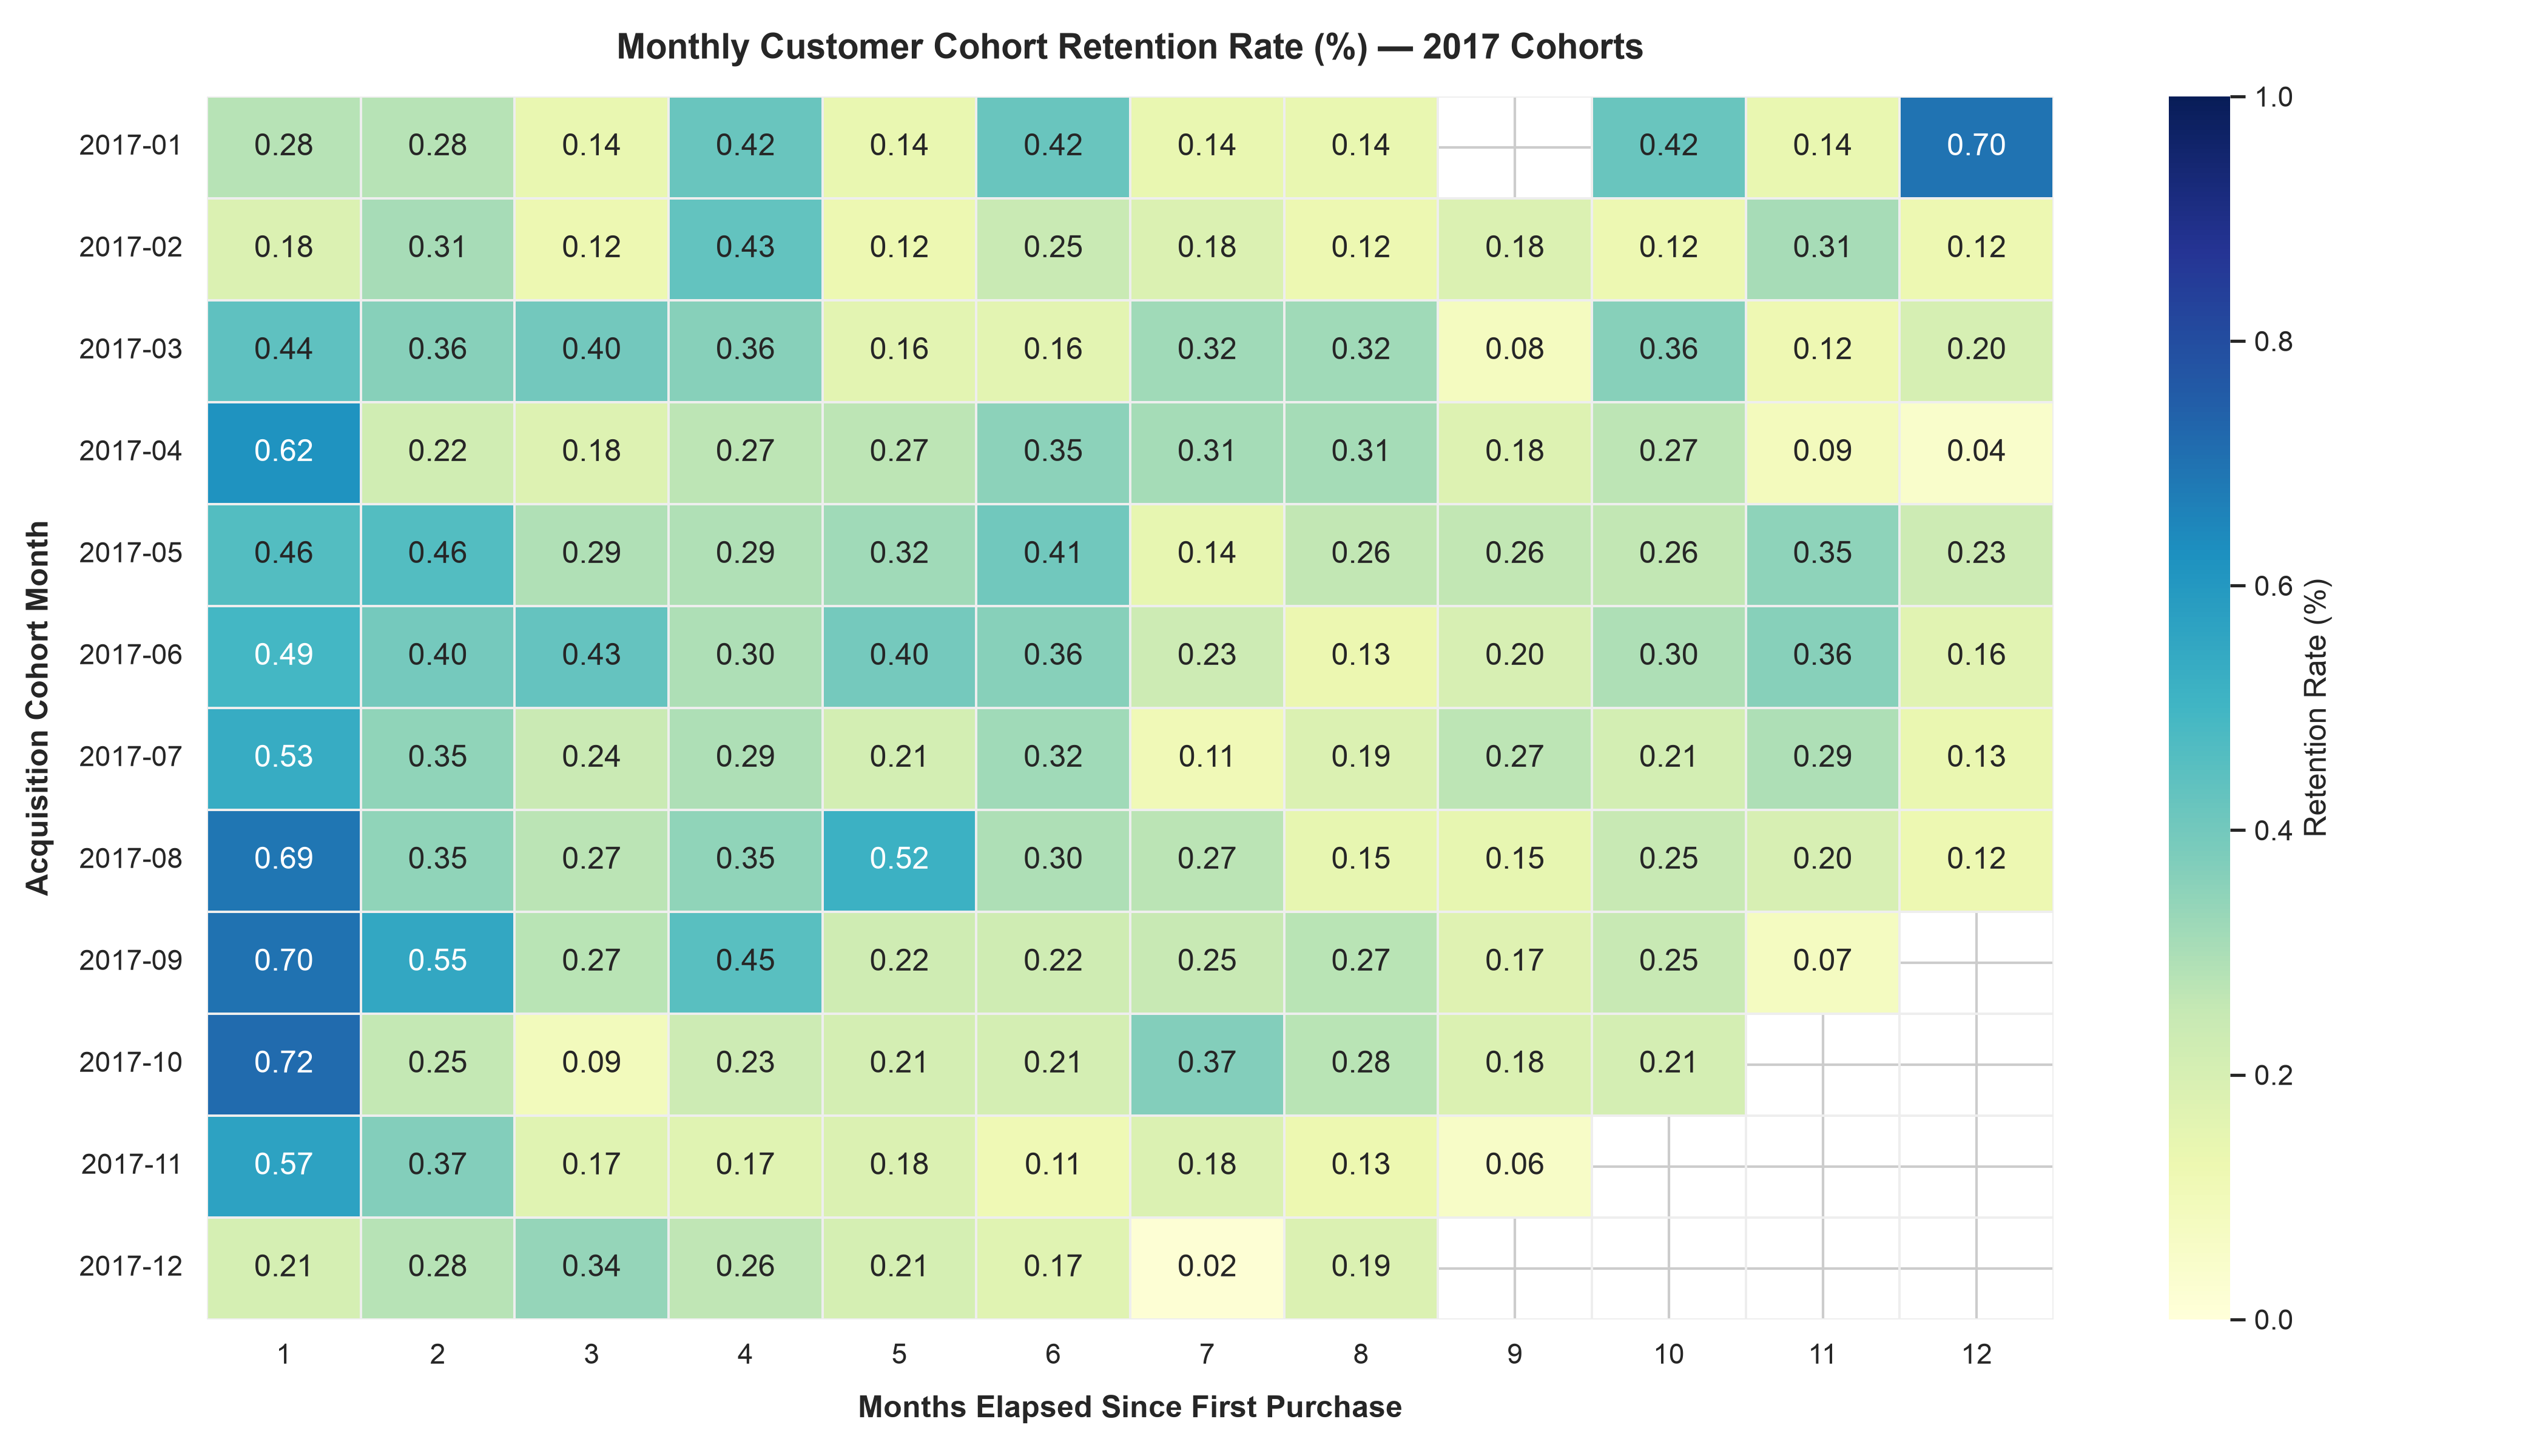

In [6]:
df_cohort = delivered_orders.merge(df_cust[["customer_id", "customer_unique_id"]], on="customer_id", how="inner").copy()
df_cohort["order_month"] = df_cohort["order_purchase_timestamp"].dt.to_period("M")
cohort_min = df_cohort.groupby("customer_unique_id")["order_month"].min().reset_index()
cohort_min.columns = ["customer_unique_id", "cohort_month"]
df_cohort = df_cohort.merge(cohort_min, on="customer_unique_id", how="left")

def get_month_diff(d1, d2):
    return (d1.year - d2.year) * 12 + (d1.month - d2.month)
df_cohort["cohort_index"] = df_cohort.apply(lambda r: get_month_diff(r["order_month"], r["cohort_month"]), axis=1)

cohort_pivot = df_cohort.groupby(["cohort_month", "cohort_index"])["customer_unique_id"].nunique().reset_index().pivot(index="cohort_month", columns="cohort_index", values="customer_unique_id")
cohort_size = cohort_pivot.iloc[:, 0]
retention_matrix = cohort_pivot.divide(cohort_size, axis=0) * 100

retention_2017 = retention_matrix.loc["2017-01":"2017-12", 1:12].copy()
retention_2017.index = [str(x) for x in retention_2017.index]

plt.figure(figsize=(14, 8))
sns.heatmap(retention_2017, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1.0, cbar_kws={"label": "Retention Rate (%)"}, linewidths=0.5, linecolor="#eeeeee")
plt.title("Monthly Customer Cohort Retention Rate (%) — 2017 Cohorts", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Months Elapsed Since First Purchase", fontsize=12, fontweight="bold", labelpad=10)
plt.ylabel("Acquisition Cohort Month", fontsize=12, fontweight="bold", labelpad=10)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "04_cohort_retention_heatmap.png"), dpi=300)
plt.show()